#  Part -01 Missing Value Handling

##  Import required libraries

In [ ]:
# Install required libraries
!pip install pandas numpy matplotlib seaborn scikit-learn joblib -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectPercentile, mutual_info_classif

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


##  Upload Dataset

In [1]:
from google.colab import files

uploaded = files.upload()

Saving smartcare_ai_dataset_1000.csv to smartcare_ai_dataset_1000.csv
Saving smartcare_ai_dataset_data_dictionary.csv to smartcare_ai_dataset_data_dictionary.csv


##  Load the uploaded dataset

In [2]:
import pandas as pd

df = pd.read_csv('smartcare_ai_dataset_1000.csv')

data = df.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1000, 33)


,record_id,patient_id,age,gender,blood_group,department,diagnosis,appointment_date,waiting_days,previous_appointments,...,consultation_fee_lkr,room_charge_lkr,lab_charge_lkr,medicine_charge_lkr,total_bill_lkr,payment_status,payment_method,no_show,readmitted_30_days,disease_risk_level
0,1,P10001,53,Male,A-,General Medicine,Migraine,2025-04-10,10,1,...,2000,0,0,11596,13596,Paid,Insurance,0,0,High
1,2,P10002,26,Male,B-,General Medicine,Diabetes,2025-05-15,2,3,...,2000,0,0,3652,5652,Paid,Insurance,0,0,Medium
2,3,P10003,22,Male,B+,Orthopedics,Back Pain,2025-07-09,22,7,...,2500,0,1200,2562,6262,Unpaid,Insurance,1,0,Medium
3,4,P10004,44,Female,AB-,Cardiology,Asthma,2025-10-16,16,1,...,2000,0,5000,10262,17262,Paid,Online,0,0,Medium
4,5,P10005,51,Female,O+,Neurology,Hypertension,2025-12-18,12,4,...,4000,0,6000,10414,20414,Paid,Cash,0,0,Medium


##  Identify missing values

In [3]:
missing_summary = pd.DataFrame({
    'Missing Values': data.isnull().sum(),
    'Missing Percentage': (
        data.isnull().sum() / len(data) * 100
    ).round(2)
})

display(
    missing_summary[
        missing_summary['Missing Values'] > 0
    ].sort_values(
        by='Missing Percentage',
        ascending=False
    )
)

,Missing Values,Missing Percentage
room_type,906,90.6


##  Visualize missing values

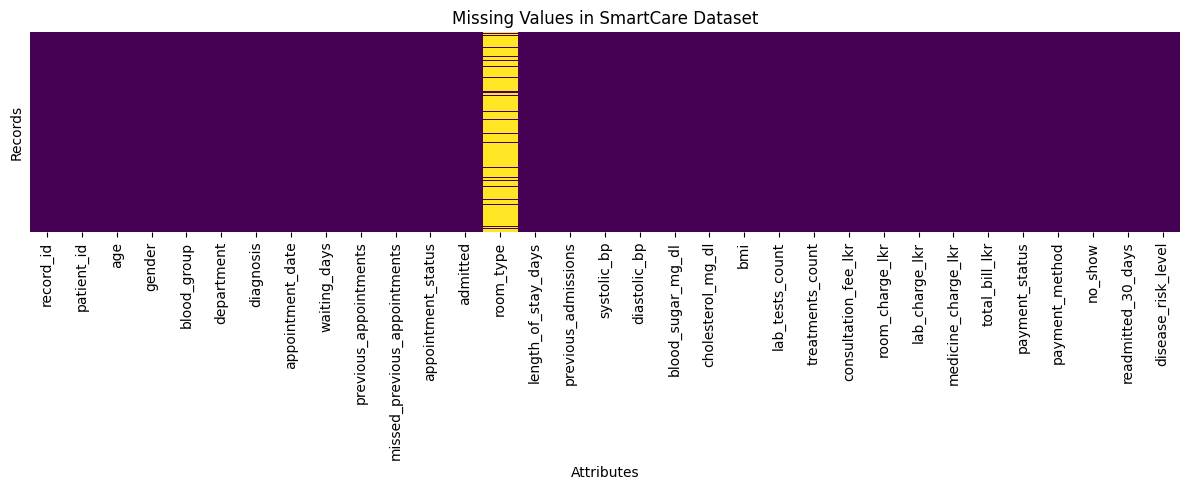

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.heatmap(
    data.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values in SmartCare Dataset')
plt.xlabel('Attributes')
plt.ylabel('Records')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

##  Handle missing values

In [6]:
# Check missing values in each column
print(data.isnull().sum())

print("\nMissing value handling will be performed")
print("using median and mode imputation after data splitting.")

record_id                         0
patient_id                        0
age                               0
gender                            0
blood_group                       0
department                        0
diagnosis                         0
appointment_date                  0
waiting_days                      0
previous_appointments             0
missed_previous_appointments      0
appointment_status                0
admitted                          0
room_type                       906
length_of_stay_days               0
previous_admissions               0
systolic_bp                       0
diastolic_bp                      0
blood_sugar_mg_dl                 0
cholesterol_mg_dl                 0
bmi                               0
lab_tests_count                   0
treatments_count                  0
consultation_fee_lkr              0
room_charge_lkr                   0
lab_charge_lkr                    0
medicine_charge_lkr               0
total_bill_lkr              

# Part -02 Duplicate Record Detection

##  Detect duplicate records

In [8]:
duplicate_count = data.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


##  Remove duplicate records

In [9]:
data = data.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", data.shape)

print("Remaining duplicates:", data.duplicated().sum())

Dataset shape after removing duplicates: (1000, 33)
Remaining duplicates: 0


#Part-03 Outlier Identification

## Identify numerical columns

In [11]:
import numpy as np

numeric_columns = data.select_dtypes(
    include=np.number
).columns.tolist()

excl_cols = [
    'record_id',
    'patient_id',
    'no_show',
    'readmitted_30_days'
]

numeric_features = [
    col for col in numeric_columns
    if col not in excl_cols
]

print("Numerical features:")
print(numeric_features)

Numerical features:
['age', 'waiting_days', 'previous_appointments', 'missed_previous_appointments', 'admitted', 'length_of_stay_days', 'previous_admissions', 'systolic_bp', 'diastolic_bp', 'blood_sugar_mg_dl', 'cholesterol_mg_dl', 'bmi', 'lab_tests_count', 'treatments_count', 'consultation_fee_lkr', 'room_charge_lkr', 'lab_charge_lkr', 'medicine_charge_lkr', 'total_bill_lkr']


##  Detect outliers using IQR

In [12]:
outlier_results = []

for column in numeric_features:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ).sum()

    outlier_results.append({
        'Feature': column,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outlier_count
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Feature,Lower Bound,Upper Bound,Outlier Count
0,age,-3.00,93.00,0
1,waiting_days,-23.50,68.50,0
2,previous_appointments,-1.00,7.00,8
3,missed_previous_appointments,-1.50,2.50,17
4,admitted,-1.50,2.50,0
5,length_of_stay_days,-3.00,5.00,48
6,previous_admissions,-1.50,2.50,60
7,systolic_bp,84.00,172.00,3
8,diastolic_bp,51.00,107.00,3
9,blood_sugar_mg_dl,44.50,184.50,10


##  Visualize outliers

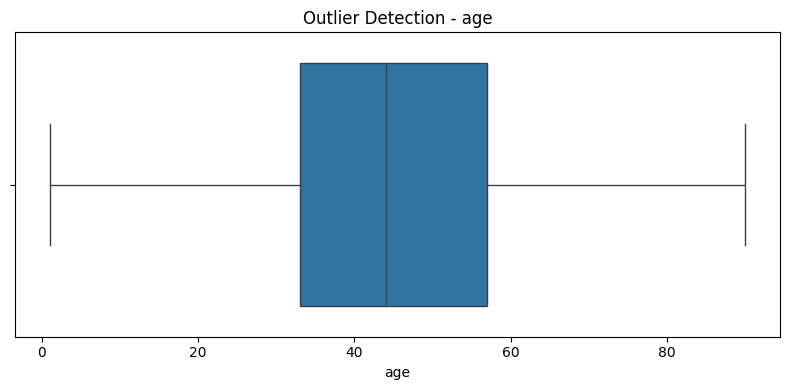

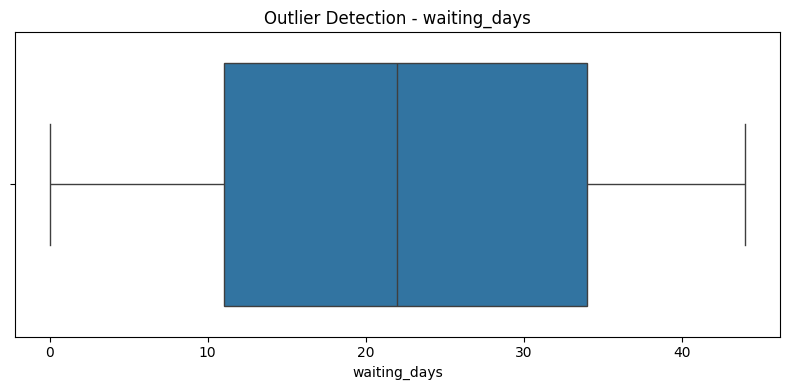

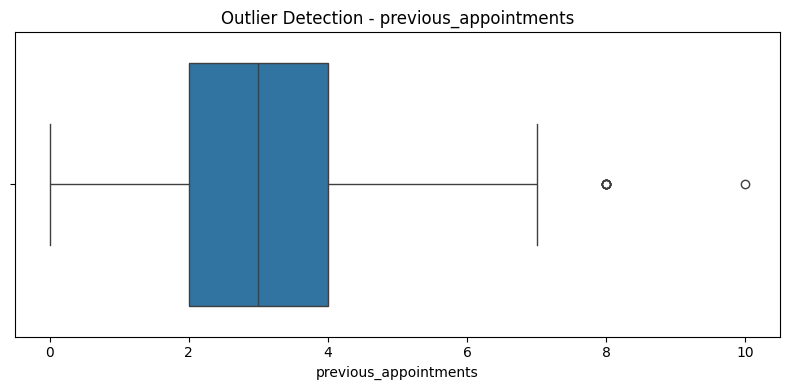

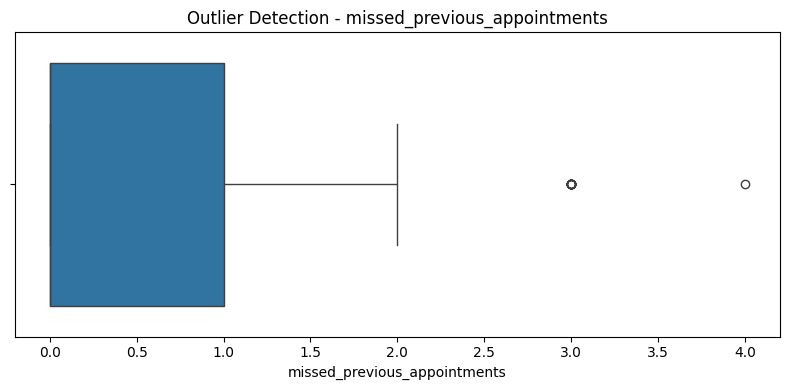

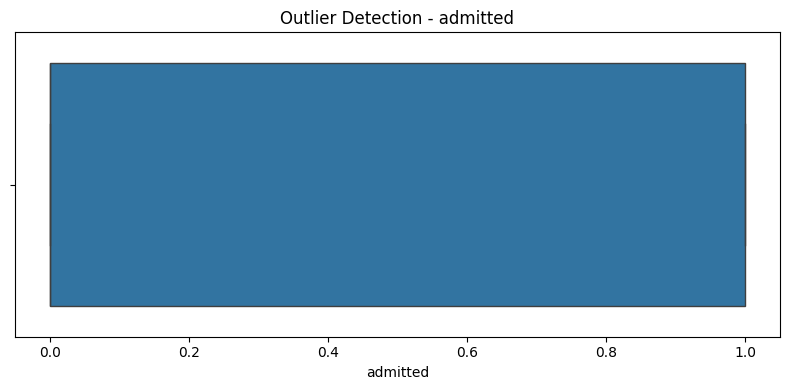

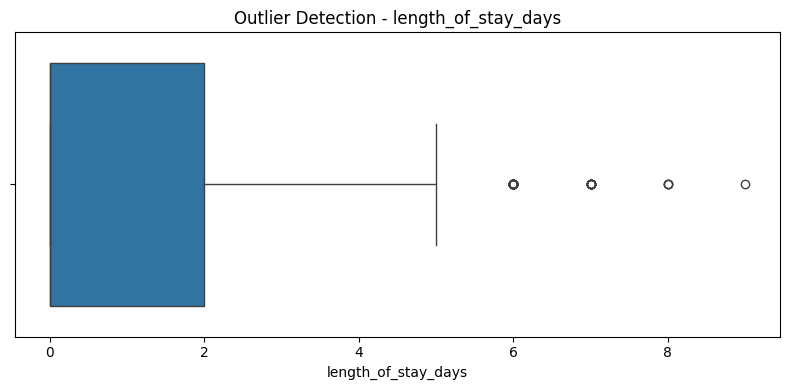

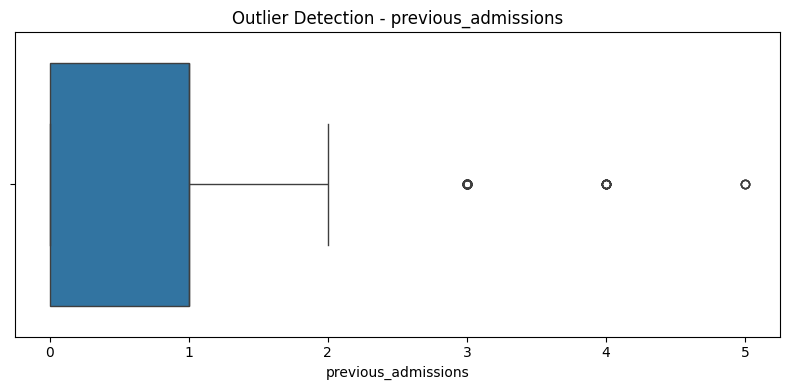

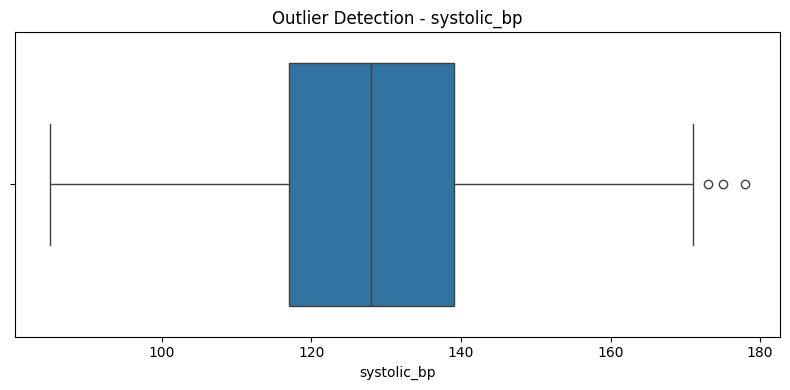

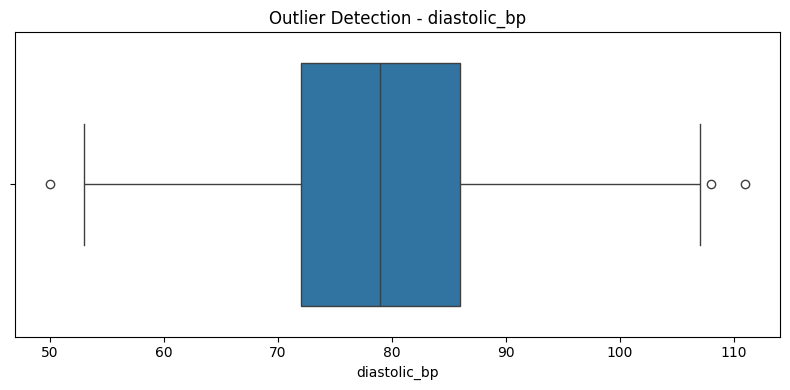

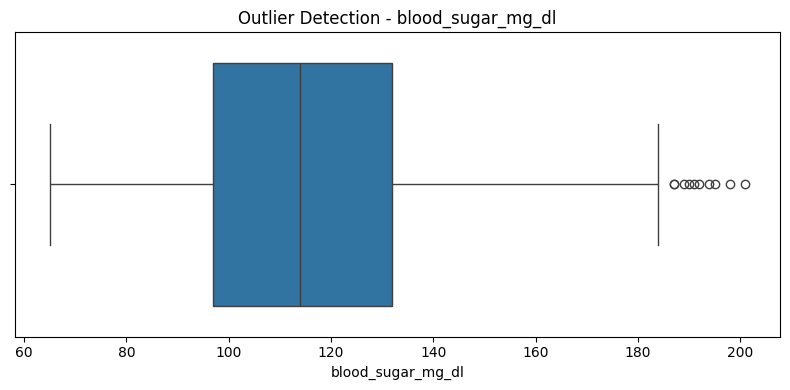

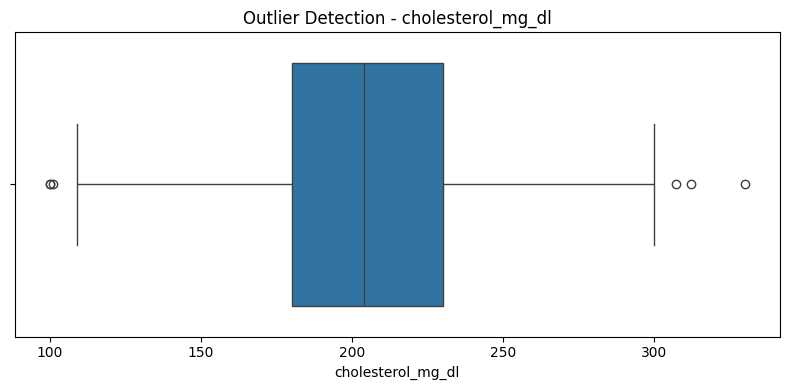

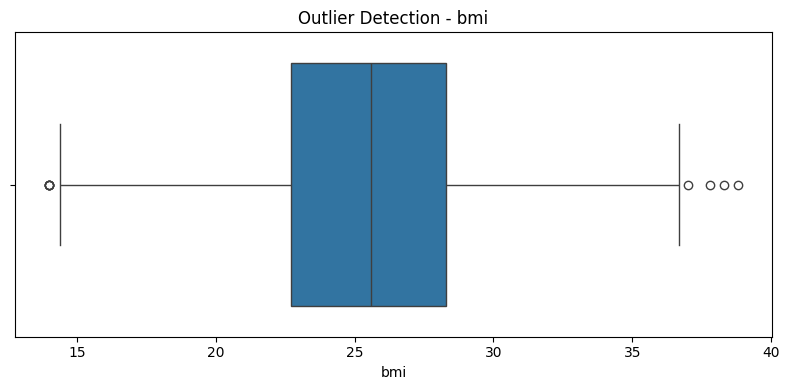

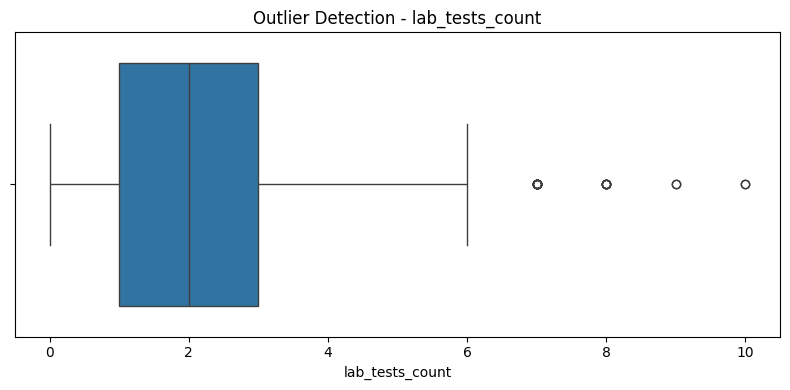

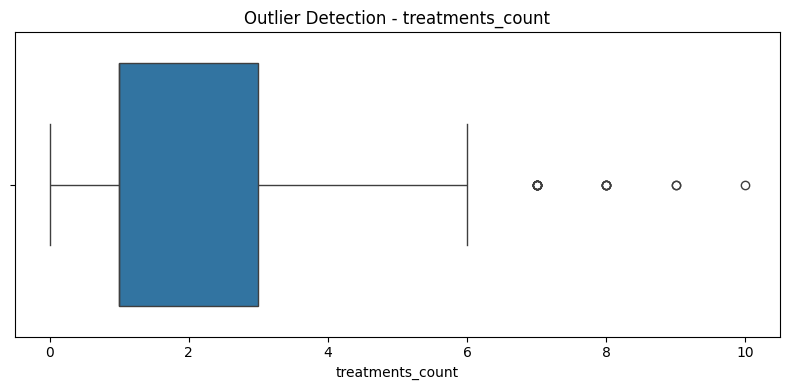

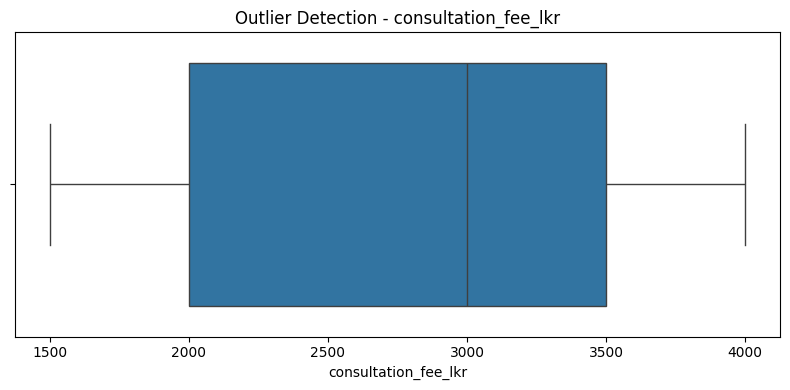

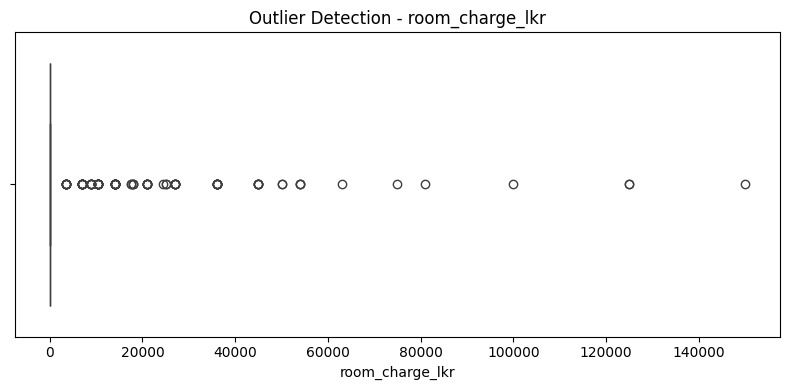

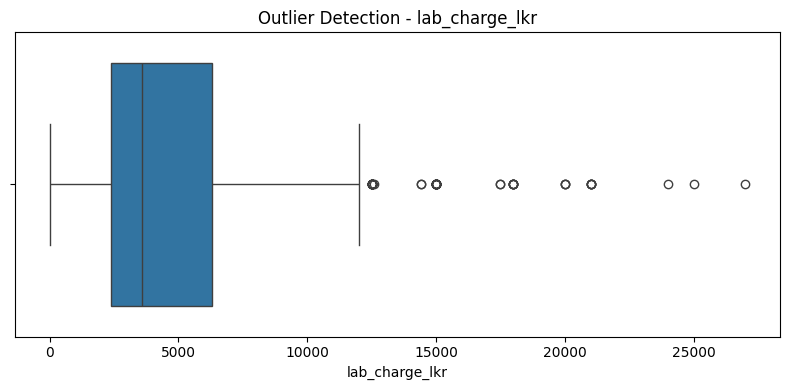

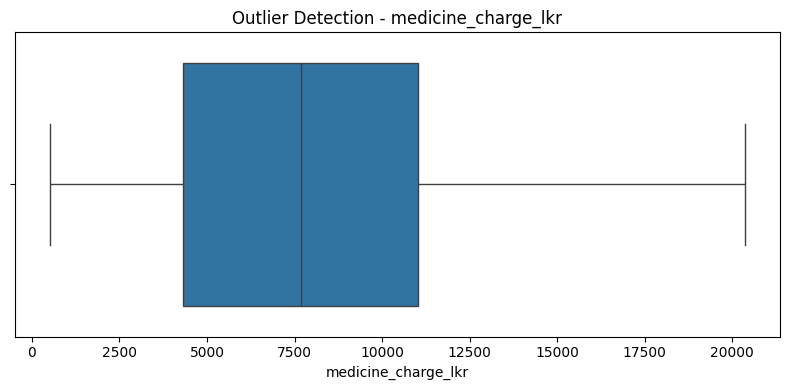

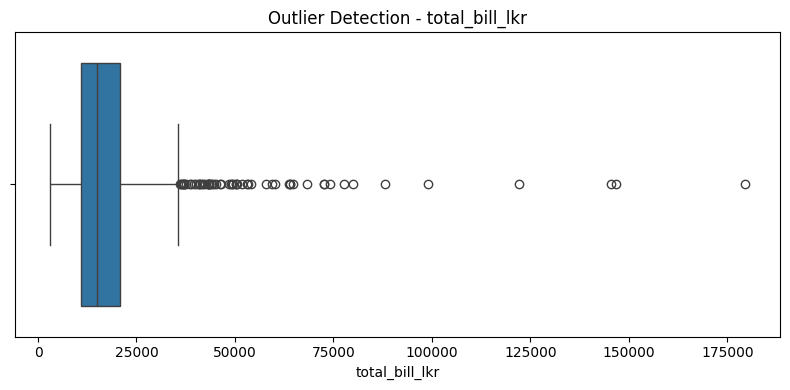

In [13]:
for column in numeric_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=data[column])

    plt.title(f'Outlier Detection - {column}')
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

#Part -04 Data Cleaning

##  Convert date and clean target variable

In [14]:
# Convert appointment date
data['appointment_date'] = pd.to_datetime(
    data['appointment_date'],
    errors='coerce'
)

# Remove records with missing target
data = data.dropna(subset=['no_show']).copy()

# Convert target to numeric
data['no_show'] = pd.to_numeric(
    data['no_show'],
    errors='coerce'
)

# Retain only valid target values
data = data[data['no_show'].isin([0, 1])].copy()

data['no_show'] = data['no_show'].astype(int)

print("Data cleaning completed!")
print("Dataset shape:", data.shape)
print("Target values:", data['no_show'].unique())

Data cleaning completed!
Dataset shape: (1000, 33)
Target values: [0 1]


##  Check data types

In [15]:
display(
    pd.DataFrame({
        'Attribute': data.columns,
        'Data Type': data.dtypes.astype(str).values
    })
)

,Attribute,Data Type
0,record_id,int64
1,patient_id,object
2,age,int64
3,gender,object
4,blood_group,object
5,department,object
6,diagnosis,object
7,appointment_date,datetime64[ns]
8,waiting_days,int64
9,previous_appointments,int64


# Part-05 Feature Encoding

##  Identify categorical and numerical features

In [16]:
target = 'no_show'

selected_features = [
    'age',
    'gender',
    'blood_group',
    'department',
    'diagnosis',
    'waiting_days',
    'previous_appointments',
    'missed_previous_appointments',
    'previous_admissions'
]

# Check selected features exist
selected_features = [
    col for col in selected_features
    if col in data.columns
]

X = data[selected_features].copy()
y = data[target].copy()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['gender', 'blood_group', 'department', 'diagnosis']
Numerical features: ['age', 'waiting_days', 'previous_appointments', 'missed_previous_appointments', 'previous_admissions']


## Split training and testing data

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (800, 9)
Testing shape: (200, 9)


## Apply One-Hot Encoding

In [18]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

categorical_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_pipeline, categorical_features)
    ],
    remainder='drop'
)

X_train_encoded = categorical_preprocessor.fit_transform(
    X_train
)

X_test_encoded = categorical_preprocessor.transform(
    X_test
)

print("Categorical encoding completed!")
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Categorical encoding completed!
Encoded training shape: (800, 27)
Encoded testing shape: (200, 27)


# Part -06 Feature Scaling

##  Apply RobustScaler to numerical features

In [19]:
 from sklearn.preprocessing import RobustScaler

numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

numerical_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features)
    ],
    remainder='drop'
)

X_train_scaled = numerical_preprocessor.fit_transform(
    X_train
)

X_test_scaled = numerical_preprocessor.transform(
    X_test
)

print("Numerical feature scaling completed!")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Numerical feature scaling completed!
Scaled training shape: (800, 5)
Scaled testing shape: (200, 5)


# Part 07-Feature Selection

##  Select relevant input variables

In [20]:
excluded_features = [
    'record_id',
    'patient_id',
    'appointment_status',
    'admitted',
    'room_type',
    'length_of_stay_days',
    'systolic_bp',
    'diastolic_bp',
    'blood_sugar_mg_dl',
    'cholesterol_mg_dl',
    'bmi',
    'lab_tests_count',
    'treatments_count',
    'consultation_fee_lkr',
    'room_charge_lkr',
    'lab_charge_lkr',
    'medicine_charge_lkr',
    'total_bill_lkr',
    'payment_status',
    'payment_method',
    'readmitted_30_days',
    'disease_risk_level'
]

print("Excluded features:")
print(excluded_features)

print("\nSelected input features:")
print(selected_features)

Excluded features:
['record_id', 'patient_id', 'appointment_status', 'admitted', 'room_type', 'length_of_stay_days', 'systolic_bp', 'diastolic_bp', 'blood_sugar_mg_dl', 'cholesterol_mg_dl', 'bmi', 'lab_tests_count', 'treatments_count', 'consultation_fee_lkr', 'room_charge_lkr', 'lab_charge_lkr', 'medicine_charge_lkr', 'total_bill_lkr', 'payment_status', 'payment_method', 'readmitted_30_days', 'disease_risk_level']

Selected input features:
['age', 'gender', 'blood_group', 'department', 'diagnosis', 'waiting_days', 'previous_appointments', 'missed_previous_appointments', 'previous_admissions']


## Apply Mutual Information feature selection

In [21]:
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import (
    SelectPercentile,
    mutual_info_classif
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from functools import partial

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', RobustScaler())
        ]), numerical_features),

        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_selector = SelectPercentile(
    score_func=partial(
        mutual_info_classif,
        random_state=42
    ),
    percentile=80
)

X_train_selected = feature_selector.fit_transform(
    X_train_processed,
    y_train
)

X_test_selected = feature_selector.transform(
    X_test_processed
)

print("Feature selection completed!")
print("Before selection:", X_train_processed.shape)
print("After selection:", X_train_selected.shape)

Feature selection completed!
Before selection: (800, 32)
After selection: (800, 25)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)


##  Display selected feature names

In [22]:
all_feature_names = preprocessor.get_feature_names_out()

selected_mask = feature_selector.get_support()

selected_feature_names = all_feature_names[selected_mask]

print("Selected features:")

for feature in selected_feature_names:
    print(feature)

print("\nTotal selected features:", len(selected_feature_names))

Selected features:
num__age
num__waiting_days
num__previous_appointments
num__missed_previous_appointments
num__previous_admissions
cat__gender_Female
cat__gender_Male
cat__blood_group_AB-
cat__blood_group_B+
cat__blood_group_B-
cat__blood_group_O-
cat__department_Cardiology
cat__department_General Medicine
cat__department_Laboratory Services
cat__department_Neurology
cat__department_Orthopedics
cat__department_Radiology
cat__diagnosis_Asthma
cat__diagnosis_Back Pain
cat__diagnosis_Chest Pain
cat__diagnosis_Diabetes
cat__diagnosis_Fever
cat__diagnosis_Fracture
cat__diagnosis_Hypertension
cat__diagnosis_Kidney Infection

Total selected features: 25


# Part 08-Feature Engineering

##  Extract appointment date features

In [23]:
data['appointment_year'] = data['appointment_date'].dt.year

data['appointment_month'] = data['appointment_date'].dt.month

data['appointment_day'] = data['appointment_date'].dt.day

data['appointment_day_of_week'] = (
    data['appointment_date'].dt.dayofweek
)

data['is_weekend'] = (
    data['appointment_day_of_week'] >= 5
).astype(int)

display(data[[
    'appointment_date',
    'appointment_year',
    'appointment_month',
    'appointment_day',
    'appointment_day_of_week',
    'is_weekend'
]].head())

,appointment_date,appointment_year,appointment_month,appointment_day,appointment_day_of_week,is_weekend
0,2025-04-10,2025,4,10,3,0
1,2025-05-15,2025,5,15,3,0
2,2025-07-09,2025,7,9,2,0
3,2025-10-16,2025,10,16,3,0
4,2025-12-18,2025,12,18,3,0


##Create additional features




In [24]:
# Previous missed appointment rate
data['previous_missed_rate'] = np.where(
    data['previous_appointments'] > 0,
    data['missed_previous_appointments'] /
    data['previous_appointments'],
    0
)

# Waiting period category
data['waiting_period_category'] = pd.cut(
    data['waiting_days'],
    bins=[-np.inf, 3, 7, 14, np.inf],
    labels=[
        'Short',
        'Medium',
        'Long',
        'Very Long'
    ]
)

display(data[[
    'previous_appointments',
    'missed_previous_appointments',
    'previous_missed_rate',
    'waiting_days',
    'waiting_period_category'
]].head())

,previous_appointments,missed_previous_appointments,previous_missed_rate,waiting_days,waiting_period_category
0,1,0,0.000000,10,Long
1,3,1,0.333333,2,Short
2,7,1,0.142857,22,Very Long
3,1,0,0.000000,16,Very Long
4,4,0,0.000000,12,Long


##  Prepare final feature set

In [25]:
final_features = [
    'age',
    'gender',
    'blood_group',
    'department',
    'diagnosis',
    'waiting_days',
    'previous_appointments',
    'missed_previous_appointments',
    'previous_admissions',
    'appointment_year',
    'appointment_month',
    'appointment_day',
    'appointment_day_of_week',
    'is_weekend',
    'previous_missed_rate',
    'waiting_period_category'
]

final_features = [
    col for col in final_features
    if col in data.columns
]

X = data[final_features].copy()
y = data['no_show'].copy()

print("Final feature set prepared!")
print("Input shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Final feature set prepared!
Input shape: (1000, 16)
Target shape: (1000,)


,age,gender,blood_group,department,diagnosis,waiting_days,previous_appointments,missed_previous_appointments,previous_admissions,appointment_year,appointment_month,appointment_day,appointment_day_of_week,is_weekend,previous_missed_rate,waiting_period_category
0,53,Male,A-,General Medicine,Migraine,10,1,0,1,2025,4,10,3,0,0.000000,Long
1,26,Male,B-,General Medicine,Diabetes,2,3,1,0,2025,5,15,3,0,0.333333,Short
2,22,Male,B+,Orthopedics,Back Pain,22,7,1,1,2025,7,9,2,0,0.142857,Very Long
3,44,Female,AB-,Cardiology,Asthma,16,1,0,0,2025,10,16,3,0,0.000000,Very Long
4,51,Female,O+,Neurology,Hypertension,12,4,0,1,2025,12,18,3,0,0.000000,Long


##  Save processed data

In [28]:
# Final output – Save your processed data
import os
import pandas as pd
import joblib

os.makedirs('../data/processed', exist_ok=True)
os.makedirs('../models', exist_ok=True)

# Ensure the selected feature names match the actual shape of the selected array
if len(X_train_selected.shape) > 1:
    num_selected_cols = X_train_selected.shape[1]
else:
    num_selected_cols = 1

actual_cols = selected_feature_names[:num_selected_cols]

# Convert to dense if sparse, and create DataFrame
if hasattr(X_train_selected, 'toarray'):
    X_train_dense = X_train_selected.toarray()
    X_test_dense = X_test_selected.toarray()
else:
    X_train_dense = X_train_selected
    X_test_dense = X_test_selected

X_train_final = pd.DataFrame(
    X_train_dense,
    columns=actual_cols
)

X_test_final = pd.DataFrame(
    X_test_dense,
    columns=actual_cols
)

X_train_final.to_csv(
    '../data/processed/X_train.csv',
    index=False
)

X_test_final.to_csv(
    '../data/processed/X_test.csv',
    index=False
)

y_train.to_frame(name='no_show').to_csv(
    '../data/processed/y_train.csv',
    index=False
)

y_test.to_frame(name='no_show').to_csv(
    '../data/processed/y_test.csv',
    index=False
)

joblib.dump(preprocessor, '../models/preprocessor.joblib')
joblib.dump(feature_selector, '../models/feature_selector.joblib')

print("Final processed data and preprocessing objects saved successfully!")

Final processed data and preprocessing objects saved successfully!


##  Download Process data

In [30]:
import shutil
import os
from google.colab import files

# Create a temporary directory to collect everything we want to download
temp_export_dir = '/content/smartcare_exports'
os.makedirs(temp_export_dir, exist_ok=True)

# Copy processed data and models to the temporary directory if they exist
if os.path.exists('../data'):
    shutil.copytree('../data', os.path.join(temp_export_dir, 'data'), dirs_exist_ok=True)
if os.path.exists('../models'):
    shutil.copytree('../models', os.path.join(temp_export_dir, 'models'), dirs_exist_ok=True)

# Create the zip archive
shutil.make_archive(
    '/content/smartcare_processed_files',
    'zip',
    temp_export_dir
)

# Download the archive
files.download('/content/smartcare_processed_files.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>